# Zadání 3 - Buzení modelu dynamické soustavy generátorem PNBS


## Frekvenční spektrum soustavy a tabulka hodnot


Maximum spektra: $S_S(0) = 4.0000$

Mezní frekvence soustavy (pokles na 5 % maxima): $f_{max} = 0.2488$ Hz ($\omega_{max} = 1.5630$ rad/s)

Tabulka frekvenčního spektra soustavy:

| $f$ [Hz] | $S_S(f)$ | $S_S(f)/S_S(f)_{max}$ | $S_S(f)/S_S(f)_{max}$ [%] |
|---:|---:|---:|---:|
| 0.0000 | 4.00000 | 1.00000 | 100.00 |
| 0.0500 | 2.78161 | 0.69540 | 69.54 |
| 0.1000 | 1.37760 | 0.34440 | 34.44 |
| 0.1500 | 0.68108 | 0.17027 | 17.03 |
| 0.2000 | 0.35675 | 0.08919 | 8.92 |
| 0.2488 | 0.20000 | 0.05000 | 5.00 |
| 0.3000 | 0.11395 | 0.02849 | 2.85 |
| 0.4000 | 0.04233 | 0.01058 | 1.06 |
| 0.5000 | 0.01763 | 0.00441 | 0.44 |
| 0.6000 | 0.00804 | 0.00201 | 0.20 |
| 0.8000 | 0.00208 | 0.00052 | 0.05 |
| 1.0000 | 0.00067 | 0.00017 | 0.02 |

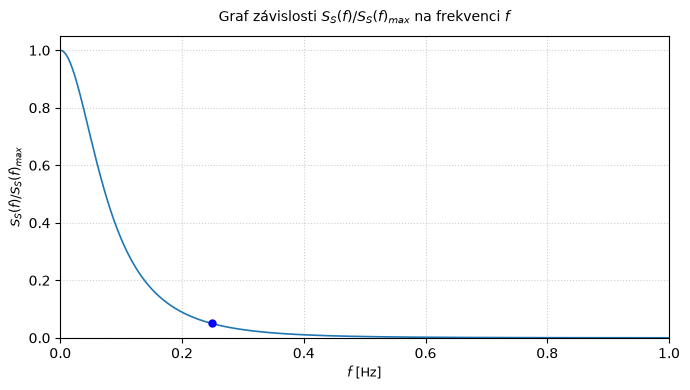

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.optimize import brentq
from IPython.display import display, Markdown

def vypis(*radky):
    display(Markdown('\n\n'.join(radky)))

def tabulka(df):
    hlavicka = '| ' + ' | '.join(df.columns) + ' |'
    oddelovac = '|' + '---:|' * len(df.columns)
    radky = ['| ' + ' | '.join(str(v) for v in r) + ' |' for r in df.itertuples(index=False)]
    display(Markdown('\n'.join([hlavicka, oddelovac] + radky)))

def sci(x, d=2):
    m, e = f'{x:.{d}e}'.split('e')
    return rf'{m} \cdot 10^{{{int(e)}}}'

K = 2.0
T1, T2, T3 = 2.0, 0.5, 0.25

def G_S(w):
    return K / ((1 + 1j * w * T1) * (1 + 1j * w * T2) * (1 + 1j * w * T3))

def S_s(f):
    w = 2 * np.pi * np.atleast_1d(f)
    return np.real(G_S(w) * G_S(-w))

S_s_max = S_s(0.0)[0]
f_max = brentq(lambda f: S_s(f)[0] / S_s_max - 0.05, 1e-3, 1.0)
w_max = 2 * np.pi * f_max

f_table = np.sort(np.array([0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00, f_max]))
Ss_vals = S_s(f_table)
Ss_norm = Ss_vals / S_s_max

df_ss = pd.DataFrame({
    r'$f$ [Hz]': [f"{v:.4f}" for v in f_table],
    r'$S_S(f)$': [f"{v:.5f}" for v in Ss_vals],
    r'$S_S(f)/S_S(f)_{max}$': [f"{v:.5f}" for v in Ss_norm],
    r'$S_S(f)/S_S(f)_{max}$ [%]': [f"{v * 100:.2f}" for v in Ss_norm]
})
vypis(rf"Maximum spektra: $S_S(0) = {S_s_max:.4f}$",
      rf"Mezní frekvence soustavy (pokles na 5 % maxima): $f_{{max}} = {f_max:.4f}$ Hz ($\omega_{{max}} = {w_max:.4f}$ rad/s)",
      "Tabulka frekvenčního spektra soustavy:")
tabulka(df_ss)
df_ss.set_axis(['f [Hz]', 'S_S(f)', 'S_S(f)/S_S(f)max', 'S_S(f)/S_S(f)max [%]'], axis=1).to_csv('tabulka_spektrum_soustavy.csv', index=False)

f_plot = np.linspace(0.0, 1.0, 1000)
Ss_plot_norm = S_s(f_plot) / S_s_max

plt.figure(figsize=(7, 4))
plt.plot(f_plot, Ss_plot_norm, color='#1F77B4', linewidth=1.2)
plt.scatter([f_max], [0.05], color='blue', s=25, zorder=5)
plt.title(r'Graf závislosti $S_S(f)/S_S(f)_{max}$ na frekvenci $f$', fontsize=10, pad=10)
plt.xlabel(r'$f$ [Hz]', fontsize=9)
plt.ylabel(r'$S_S(f)/S_S(f)_{max}$', fontsize=9)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.05)
plt.xticks(np.arange(0.0, 1.1, 0.2))
plt.yticks(np.arange(0.0, 1.1, 0.2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("spektrum_soustavy.png", dpi=300)
plt.show()


## Návrh parametrů generátoru PNBS


In [9]:
def S_g(f, dt, a):
    f = np.atleast_1d(np.asarray(f, dtype=float))
    res = np.full_like(f, a ** 2 * dt)
    nenula = f != 0
    res[nenula] = a ** 2 * (1 - np.cos(2 * np.pi * f[nenula] * dt)) / (2 * np.pi ** 2 * f[nenula] ** 2 * dt)
    return res

x_lim = brentq(lambda x: (np.sin(x) / x) ** 2 - 0.95, 1e-3, 1.0)
dt_max_spektrum = x_lim / (np.pi * f_max)

T_max = max(T1, T2, T3)
dt_max_tmax = 0.314 * T_max

delta_t = 0.5
a_amp = 1.0
n_bits = 6

Sg_at_fmax = S_g(f_max, delta_t, a_amp)[0] / S_g(0.0, delta_t, a_amp)[0]
pokles_pnbs = (1.0 - Sg_at_fmax) * 100

vypis(rf"Podmínka $S_G(f_{{max}})/S_G(0) \ge 0.95$: $\pi f_{{max}} \Delta t \le {x_lim:.4f}$, tedy $\Delta t \le {dt_max_spektrum:.4f}$ s",
      rf"Zvolený interval hodinových impulsů: $\Delta t = {delta_t}$ s",
      rf"Zvolená amplituda: $a = {a_amp}$",
      rf"Zvolený počet stupňů posuvného registru: $n = {n_bits}$",
      rf"Hodnota spektra PNBS při $f_{{max}}$: $S_G(f_{{max}})/S_G(0) = {Sg_at_fmax:.4f}$ (pokles {pokles_pnbs:.2f} % $\le$ 5 %): {pokles_pnbs <= 5}")
      

Podmínka $S_G(f_{max})/S_G(0) \ge 0.95$: $\pi f_{max} \Delta t \le 0.3913$, tedy $\Delta t \le 0.5007$ s

Zvolený interval hodinových impulsů: $\Delta t = 0.5$ s

Zvolená amplituda: $a = 1.0$

Zvolený počet stupňů posuvného registru: $n = 6$

Hodnota spektra PNBS při $f_{max}$: $S_G(f_{max})/S_G(0) = 0.9501$ (pokles 4.99 % $\le$ 5 %): True

## Kontrola parametrů pomocí maximální časové konstanty $T_{max}$


In [10]:
f_dolni = 0.5 / (2 * np.pi * T_max)
f_horni = 10 / (2 * np.pi * T_max)
f_h = 0.5 / delta_t

vypis(rf"Maximální časová konstanta soustavy: $T_{{max}} = {T_max:.1f}$ s",
      rf"Pásmo rozhodující pro dynamiku soustavy: $f_{{dolní}} = 0.5/(2\pi T_{{max}}) = {f_dolni:.4f}$ Hz, $f_{{horní}} = 10/(2\pi T_{{max}}) = {f_horni:.4f}$ Hz",
      rf"Nejvyšší frekvence spektra PNBS: $f_h = 0.5/\Delta t = {f_h:.4f}$ Hz $>$ $f_{{horní}}$: {f_h > f_horni}",
      rf"Podmínka $\Delta t < 0.314\,T_{{max}} = {dt_max_tmax:.3f}$ s: $\Delta t = {delta_t}$ s, splněno: {delta_t < dt_max_tmax}",
      rf"Podmínka $N \Delta t > 12.56\,T_{{max}} = {12.56 * T_max:.2f}$ s, tedy $f_d = 1/(N \Delta t) < f_{{dolní}}$, pro různá $n$:")

radky = []
for n_test in range(3, 10):
    N_test = 2 ** n_test - 1
    T_G_test = N_test * delta_t
    radky.append([n_test, N_test, f"{T_G_test:.1f}", f"{1 / T_G_test:.4f}", 'ano' if T_G_test > 12.56 * T_max else 'ne'])
tabulka(pd.DataFrame(radky, columns=[r'$n$', r'$N = 2^n - 1$', r'$T_G = N \Delta t$ [s]', r'$f_d$ [Hz]', rf'$N \Delta t > {12.56 * T_max:.2f}$ s']))

N_pnbs = 2 ** n_bits - 1
T_G = N_pnbs * delta_t
vypis(rf"Zvoleno $n = {n_bits}$: $N = {N_pnbs}$, $T_G = {T_G:.1f}$ s $>$ ${12.56 * T_max:.2f}$ s: {T_G > 12.56 * T_max}")


Maximální časová konstanta soustavy: $T_{max} = 2.0$ s

Pásmo rozhodující pro dynamiku soustavy: $f_{dolní} = 0.5/(2\pi T_{max}) = 0.0398$ Hz, $f_{horní} = 10/(2\pi T_{max}) = 0.7958$ Hz

Nejvyšší frekvence spektra PNBS: $f_h = 0.5/\Delta t = 1.0000$ Hz $>$ $f_{horní}$: True

Podmínka $\Delta t < 0.314\,T_{max} = 0.628$ s: $\Delta t = 0.5$ s, splněno: True

Podmínka $N \Delta t > 12.56\,T_{max} = 25.12$ s, tedy $f_d = 1/(N \Delta t) < f_{dolní}$, pro různá $n$:

| $n$ | $N = 2^n - 1$ | $T_G = N \Delta t$ [s] | $f_d$ [Hz] | $N \Delta t > 25.12$ s |
|---:|---:|---:|---:|---:|
| 3 | 7 | 3.5 | 0.2857 | ne |
| 4 | 15 | 7.5 | 0.1333 | ne |
| 5 | 31 | 15.5 | 0.0645 | ne |
| 6 | 63 | 31.5 | 0.0317 | ano |
| 7 | 127 | 63.5 | 0.0157 | ano |
| 8 | 255 | 127.5 | 0.0078 | ano |
| 9 | 511 | 255.5 | 0.0039 | ano |

Zvoleno $n = 6$: $N = 63$, $T_G = 31.5$ s $>$ $25.12$ s: True

## Výkonová spektrální hustota generátoru PNBS a porovnání se spektrem soustavy


Limita pro $f \to 0$: $S_G(0) = a^2 \Delta t = 0.5000$

Tabulka výkonové spektrální hustoty PNBS:

| $f$ [Hz] | $S_G(f)$ | $S_G(f)/S_G(f)_{max}$ | $S_G(f)/S_G(f)_{max}$ [%] |
|---:|---:|---:|---:|
| 0.0000 | 0.50000 | 1.00000 | 100.00 |
| 0.0500 | 0.49897 | 0.99795 | 99.79 |
| 0.1000 | 0.49590 | 0.99180 | 99.18 |
| 0.1500 | 0.49082 | 0.98163 | 98.16 |
| 0.2000 | 0.48377 | 0.96753 | 96.75 |
| 0.2488 | 0.47506 | 0.95013 | 95.01 |
| 0.3000 | 0.46407 | 0.92814 | 92.81 |
| 0.4000 | 0.43757 | 0.87514 | 87.51 |
| 0.5000 | 0.40528 | 0.81057 | 81.06 |
| 0.6000 | 0.36842 | 0.73684 | 73.68 |
| 0.8000 | 0.28639 | 0.57279 | 57.28 |
| 1.0000 | 0.20264 | 0.40528 | 40.53 |

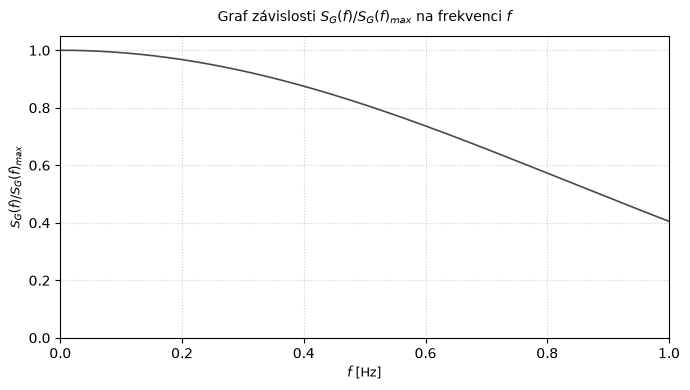

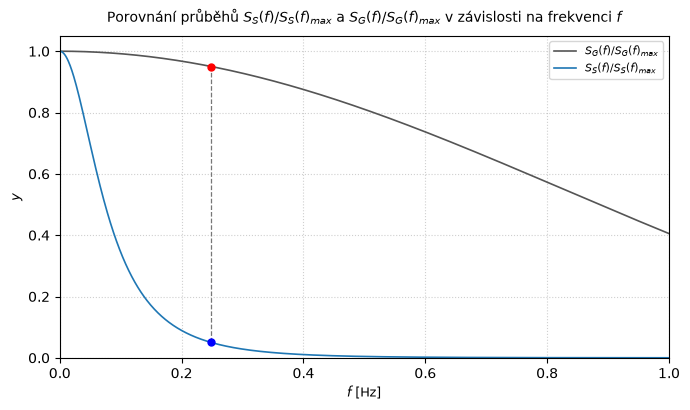

Spektrum soustavy při $f_{max}$: 0.0500, spektrum PNBS při $f_{max}$: 0.9501

Pokles spektra PNBS v bodě $f_{max}$: 4.99 %

In [11]:
Sg_vals = S_g(f_table, delta_t, a_amp)
Sg_max = S_g(0.0, delta_t, a_amp)[0]
Sg_norm = Sg_vals / Sg_max

df_sg = pd.DataFrame({
    r'$f$ [Hz]': [f"{v:.4f}" for v in f_table],
    r'$S_G(f)$': [f"{v:.5f}" for v in Sg_vals],
    r'$S_G(f)/S_G(f)_{max}$': [f"{v:.5f}" for v in Sg_norm],
    r'$S_G(f)/S_G(f)_{max}$ [%]': [f"{v * 100:.2f}" for v in Sg_norm]
})
vypis(rf"Limita pro $f \to 0$: $S_G(0) = a^2 \Delta t = {Sg_max:.4f}$", "Tabulka výkonové spektrální hustoty PNBS:")
tabulka(df_sg)
df_sg.set_axis(['f [Hz]', 'S_G(f)', 'S_G(f)/S_G(f)max', 'S_G(f)/S_G(f)max [%]'], axis=1).to_csv('tabulka_spektrum_pnbs.csv', index=False)

Sg_plot_norm = S_g(f_plot, delta_t, a_amp) / Sg_max

plt.figure(figsize=(7, 4))
plt.plot(f_plot, Sg_plot_norm, color='#4A4A4A', linewidth=1.2)
plt.title(r'Graf závislosti $S_G(f)/S_G(f)_{max}$ na frekvenci $f$', fontsize=10, pad=10)
plt.xlabel(r'$f$ [Hz]', fontsize=9)
plt.ylabel(r'$S_G(f)/S_G(f)_{max}$', fontsize=9)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.05)
plt.xticks(np.arange(0.0, 1.1, 0.2))
plt.yticks(np.arange(0.0, 1.1, 0.2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("spektrum_pnbs.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 4.2))
plt.plot(f_plot, Sg_plot_norm, color='#555555', linewidth=1.2, label=r'$S_G(f)/S_G(f)_{max}$')
plt.plot(f_plot, Ss_plot_norm, color='#1F77B4', linewidth=1.2, label=r'$S_S(f)/S_S(f)_{max}$')
plt.plot([f_max, f_max], [0.05, Sg_at_fmax], color='#777777', linestyle='--', linewidth=0.9)
plt.scatter([f_max], [0.05], color='blue', s=25, zorder=5)
plt.scatter([f_max], [Sg_at_fmax], color='red', s=25, zorder=5)
plt.title(r'Porovnání průběhů $S_S(f)/S_S(f)_{max}$ a $S_G(f)/S_G(f)_{max}$ v závislosti na frekvenci $f$', fontsize=10, pad=10)
plt.xlabel(r'$f$ [Hz]', fontsize=9)
plt.ylabel(r'$y$', fontsize=9)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.05)
plt.xticks(np.arange(0.0, 1.1, 0.2))
plt.yticks(np.arange(0.0, 1.1, 0.2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig("spektrum_porovnani.png", dpi=300)
plt.show()

vypis(rf"Spektrum soustavy při $f_{{max}}$: {0.05:.4f}, spektrum PNBS při $f_{{max}}$: {Sg_at_fmax:.4f}",
      rf"Pokles spektra PNBS v bodě $f_{{max}}$: {pokles_pnbs:.2f} %")
      

## Diskrétní přenos a diferenční rovnice vyšetřované soustavy


In [12]:
T0 = delta_t
num_s = [K]
den_s = [T1 * T2 * T3, T1 * T2 + T1 * T3 + T2 * T3, T1 + T2 + T3, 1.0]

b_z, a_z, _ = signal.cont2discrete((num_s, den_s), T0, method='zoh')
b_z = b_z.flatten()
a_z = a_z.flatten()

koef = lambda v: ', '.join(f'{c:.5f}' for c in v)
vypis(rf"Spojitý přenos: $G_S(s) = \dfrac{{{K:g}}}{{{den_s[0]:g}s^3 + {den_s[1]:g}s^2 + {den_s[2]:g}s + 1}}$",
      rf"Perioda vzorkování: $T_0 = \Delta t = {T0}$ s",
      rf"Čitatel $B(z^{{-1}})$, koeficienty u $z^0, z^{{-1}}, z^{{-2}}, z^{{-3}}$: {koef(b_z)}",
      rf"Jmenovatel $A(z^{{-1}})$, koeficienty u $z^0, z^{{-1}}, z^{{-2}}, z^{{-3}}$: {koef(a_z)}",
      "Diferenční rovnice:",
      rf"$y(k) = {-a_z[1]:.5f}\,y(k-1) {-a_z[2]:+.5f}\,y(k-2) {-a_z[3]:+.5f}\,y(k-3) {b_z[1]:+.5f}\,u(k-1) {b_z[2]:+.5f}\,u(k-2) {b_z[3]:+.5f}\,u(k-3)$")

poly_s = np.roots(den_s)
poly_z = np.roots(a_z)
t_step = np.arange(0, 40 * T0, T0)
y_spoj = signal.step((num_s, den_s), T=t_step)[1]
y_disk = signal.lfilter(b_z, a_z, np.ones_like(t_step))

vypis(rf"Póly spojité soustavy: {', '.join(f'{p:.4f}' for p in np.sort(poly_s.real))}",
      rf"Póly diskrétní soustavy: {', '.join(f'{p:.5f}' for p in np.sort(poly_z.real))} (hodnoty $e^{{-T_0/T_i}}$: {', '.join(f'{p:.5f}' for p in np.sort(np.exp(-T0 / np.array([T1, T2, T3]))))})",
      rf"Statické zesílení $G_S(z=1) = {np.sum(b_z) / np.sum(a_z):.4f}$ (spojitě {K:.4f})",
      rf"Max. odchylka skokové odezvy diskrétního a spojitého modelu ve vzorcích: ${sci(np.max(np.abs(y_spoj - y_disk)))}$")
      

Spojitý přenos: $G_S(s) = \dfrac{2}{0.25s^3 + 1.625s^2 + 2.75s + 1}$

Perioda vzorkování: $T_0 = \Delta t = 0.5$ s

Čitatel $B(z^{-1})$, koeficienty u $z^0, z^{-1}, z^{-2}, z^{-3}$: 0.00000, 0.07835, 0.14794, 0.01551

Jmenovatel $A(z^{-1})$, koeficienty u $z^0, z^{-1}, z^{-2}, z^{-3}$: 1.00000, -1.28202, 0.44169, -0.03877

Diferenční rovnice:

$y(k) = 1.28202\,y(k-1) -0.44169\,y(k-2) +0.03877\,y(k-3) +0.07835\,u(k-1) +0.14794\,u(k-2) +0.01551\,u(k-3)$

Póly spojité soustavy: -4.0000, -2.0000, -0.5000

Póly diskrétní soustavy: 0.13534, 0.36788, 0.77880 (hodnoty $e^{-T_0/T_i}$: 0.13534, 0.36788, 0.77880)

Statické zesílení $G_S(z=1) = 2.0000$ (spojitě 2.0000)

Max. odchylka skokové odezvy diskrétního a spojitého modelu ve vzorcích: $1.11 \cdot 10^{-15}$

## Generování PNBS, simulace odezvy soustavy a export dat


Zpětná vazba: $x^{6} + x^{5} + 1$

Délka periody generátoru: $N = 63$

Počet hodnot $a$ / $0$ v jedné periodě: 32/31

Počet různých 6prvkových posloupností: 63 (maximální délka registru: True)

Počet uložených vzorků: $315 = 5 \cdot N$

Max. rozdíl diferenční rovnice a funkce `lfilter`: $6.66 \cdot 10^{-16}$

Prvních 5 řádků uložených dat $[k, u(k), y(k)]$:

| $k$ | $u(k)$ | $y(k)$ |
|---:|---:|---:|
| 1 | 1.0 | 0.00000 |
| 2 | 1.0 | 0.07835 |
| 3 | 1.0 | 0.32674 |
| 4 | 1.0 | 0.62608 |
| 5 | 1.0 | 0.90317 |

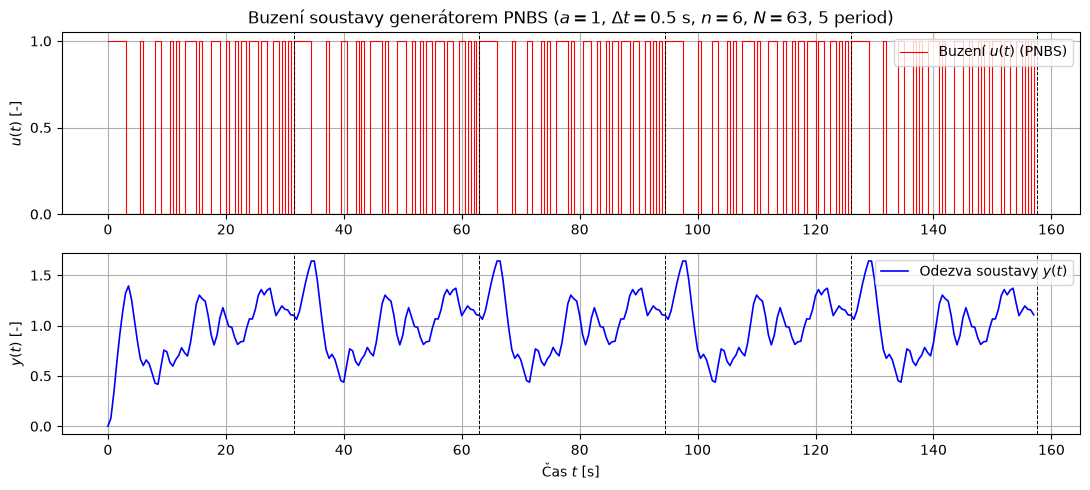

In [13]:
def pnbs(n, a, odbocky):
    N = 2 ** n - 1
    reg = np.ones(n, dtype=int)
    u = np.zeros(N)
    for i in range(N):
        u[i] = a if reg[-1] == 1 else 0.0
        zpetna_vazba = reg[odbocky[0] - 1] ^ reg[odbocky[1] - 1]
        reg = np.roll(reg, 1)
        reg[0] = zpetna_vazba
    return u

u_perioda = pnbs(n_bits, a_amp, odbocky=(n_bits, n_bits - 1))

stavy = {tuple(u_perioda[i:i + n_bits]) for i in range(N_pnbs)}
vypis(rf"Zpětná vazba: $x^{{{n_bits}}} + x^{{{n_bits - 1}}} + 1$",
      rf"Délka periody generátoru: $N = {len(u_perioda)}$",
      rf"Počet hodnot $a$ / $0$ v jedné periodě: {int(np.sum(u_perioda > 0))}/{int(np.sum(u_perioda == 0))}",
      rf"Počet různých {n_bits}prvkových posloupností: {len(stavy)} (maximální délka registru: {len(stavy) == N_pnbs})")

n_periods = 5
u_seq = np.tile(u_perioda, n_periods)
K_total = len(u_seq)
k_vec = np.arange(1, K_total + 1)
t_vec = (k_vec - 1) * T0

y_seq = np.zeros(K_total)
for k in range(K_total):
    y_seq[k] = (-a_z[1] * (y_seq[k - 1] if k >= 1 else 0.0)
                - a_z[2] * (y_seq[k - 2] if k >= 2 else 0.0)
                - a_z[3] * (y_seq[k - 3] if k >= 3 else 0.0)
                + b_z[1] * (u_seq[k - 1] if k >= 1 else 0.0)
                + b_z[2] * (u_seq[k - 2] if k >= 2 else 0.0)
                + b_z[3] * (u_seq[k - 3] if k >= 3 else 0.0))

y_lfilter = signal.lfilter(b_z, a_z, u_seq)

data = np.column_stack([k_vec, u_seq, y_seq])
np.savetxt('data_pnbs.csv', data, delimiter=',', header='k,u(k),y(k)', comments='', fmt=['%d', '%.1f', '%.8f'])

vypis(rf"Počet uložených vzorků: ${K_total} = {n_periods} \cdot N$",
      rf"Max. rozdíl diferenční rovnice a funkce `lfilter`: ${sci(np.max(np.abs(y_seq - y_lfilter)))}$",
      r"Prvních 5 řádků uložených dat $[k, u(k), y(k)]$:")
tabulka(pd.DataFrame({r'$k$': data[:5, 0].astype(int), r'$u(k)$': [f'{v:.1f}' for v in data[:5, 1]], r'$y(k)$': [f'{v:.5f}' for v in data[:5, 2]]}))

plt.figure(figsize=(11, 5))
plt.subplot(2, 1, 1)
plt.step(t_vec, u_seq, 'r-', where='post', linewidth=0.8, label=r'Buzení $u(t)$ (PNBS)')
for p in range(1, n_periods + 1):
    plt.axvline(p * T_G, color='k', linestyle='--', linewidth=0.7)
plt.ylabel(r'$u(t)$ [-]')
plt.ylim(0.0, 1.05)
plt.yticks([0.0, 0.5, 1.0])
plt.title(rf'Buzení soustavy generátorem PNBS ($a={a_amp:.0f}$, $\Delta t={delta_t}$ s, $n={n_bits}$, $N={N_pnbs}$, 5 period)')
plt.grid(True)
plt.legend(loc='upper right')

plt.subplot(2, 1, 2)
plt.plot(t_vec, y_seq, 'b-', linewidth=1.2, label=r'Odezva soustavy $y(t)$')
for p in range(1, n_periods + 1):
    plt.axvline(p * T_G, color='k', linestyle='--', linewidth=0.7)
plt.xlabel(r'Čas $t$ [s]')
plt.ylabel(r'$y(t)$ [-]')
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig("pnbs_odezva.png", dpi=300)
plt.show()


## Ověření frekvenčních vlastností generovaných dat


$R_{uu}(0) = 1.0000$, $R_{uu}(N) = 1.0000$, $R_{uu}(2N) = 1.0000$

Cyklická autokorelace jedné periody: $R(0) = 1.00000$, $R(i) = -0.01613$ pro $i = 1, \dots, N-1$ (teoreticky $-1/(N-1) = -0.01613$, max. odchylka $6.25 \cdot 10^{-17}$)

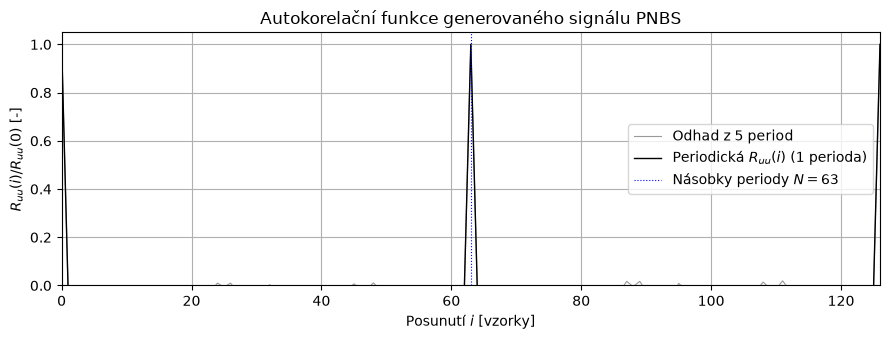

Max. rozdíl odezvy mezi 2. a 5. periodou (ustálenost): $2.06 \cdot 10^{-7}$

Max. rozdíl odhadu $G(f)$ z dat a $G_S(z)$ na harmonických: $2.17 \cdot 10^{-7}$

Harmonických ve frekvenčním pásmu soustavy ($f \le f_{max}$): 7, krok 0.0317 Hz

Max. odchylka $\lvert \hat G(f) \rvert^2$ z dat od $S_S(f)$ v pásmu $f \le f_{max}$: 4.31 %

Výkon harmonických vzorkovaného PNBS $\lvert U(k) \rvert^2/(N+1)$: min 1.00000, max 1.00000 (rovnoměrné)

Max. odchylka výkonu harmonických PNBS (s držením) od obálky $S_G(f)/S_G(f)_{max}$: $6.66 \cdot 10^{-16}$

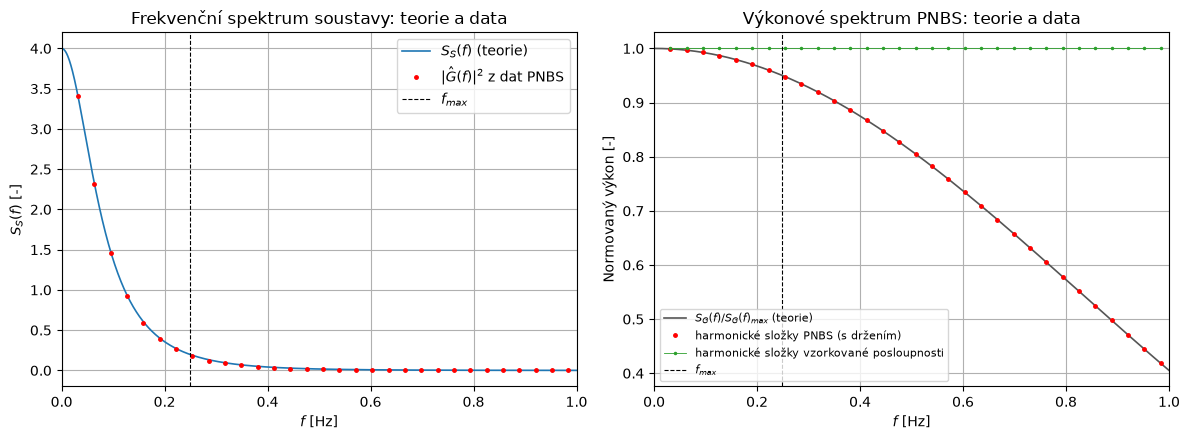

In [14]:
max_lag = 2 * N_pnbs
lags = np.arange(0, max_lag + 1)
u_c = u_seq - np.mean(u_perioda)
R_uu = np.array([np.sum(u_c[:K_total - i] * u_c[i:]) / (K_total - i) for i in lags])
R_uu = R_uu / R_uu[0]
R_cyk = np.real(np.fft.ifft(np.abs(np.fft.fft(u_perioda - np.mean(u_perioda))) ** 2))
R_cyk = R_cyk / R_cyk[0]

vypis(rf"$R_{{uu}}(0) = {R_uu[0]:.4f}$, $R_{{uu}}(N) = {R_uu[N_pnbs]:.4f}$, $R_{{uu}}(2N) = {R_uu[2 * N_pnbs]:.4f}$",
      rf"Cyklická autokorelace jedné periody: $R(0) = {R_cyk[0]:.5f}$, $R(i) = {np.mean(R_cyk[1:]):.5f}$ pro $i = 1, \dots, N-1$ (teoreticky $-1/(N-1) = {-1 / (N_pnbs - 1):.5f}$, max. odchylka ${sci(np.max(np.abs(R_cyk[1:] + 1 / (N_pnbs - 1))))}$)")

plt.figure(figsize=(9, 3.5))
plt.plot(lags, R_uu, color='0.6', linewidth=0.8, label=r'Odhad z 5 period')
plt.plot(lags, R_cyk[lags % N_pnbs], 'k-', linewidth=1.0, label=r'Periodická $R_{uu}(i)$ (1 perioda)')
for p in (1, 2):
    plt.axvline(p * N_pnbs, color='blue', linestyle=':', linewidth=0.8, label=rf'Násobky periody $N={N_pnbs}$' if p == 1 else None)
plt.title(r'Autokorelační funkce generovaného signálu PNBS')
plt.xlabel(r'Posunutí $i$ [vzorky]')
plt.ylabel(r'$R_{uu}(i) / R_{uu}(0)$ [-]')
plt.xlim(0, max_lag)
plt.ylim(0.0, 1.05)
plt.grid(True)
plt.legend(loc='center right')
plt.tight_layout()
plt.savefig("pnbs_autokorelace.png", dpi=300)
plt.show()

u_ust = u_seq[N_pnbs:]
y_ust = y_seq[N_pnbs:]
U = np.fft.rfft(u_ust[:N_pnbs])
Y = np.fft.rfft(y_ust[:N_pnbs])
f_harm = np.fft.rfftfreq(N_pnbs, d=T0)
rozdil_period = np.max(np.abs(y_ust[:N_pnbs] - y_ust[3 * N_pnbs:4 * N_pnbs]))

G_odhad = Y[1:] / U[1:]
f_h = f_harm[1:]
zinv = np.exp(-1j * 2 * np.pi * f_h * T0)
G_disk = np.polyval(b_z[::-1], zinv) / np.polyval(a_z[::-1], zinv)
S_odhad = np.abs(G_odhad) ** 2

pasmo = f_h <= f_max
odchylka_pasmo = np.abs(S_odhad[pasmo] / S_s(f_h[pasmo]) - 1) * 100

P_vzork = np.abs(U[1:]) ** 2 / (N_pnbs + 1) / (a_amp / 2) ** 2
P_drzeny = P_vzork * S_g(f_h, delta_t, a_amp) / Sg_max

vypis(rf"Max. rozdíl odezvy mezi 2. a 5. periodou (ustálenost): ${sci(rozdil_period)}$",
      rf"Max. rozdíl odhadu $G(f)$ z dat a $G_S(z)$ na harmonických: ${sci(np.max(np.abs(G_odhad - G_disk)))}$",
      rf"Harmonických ve frekvenčním pásmu soustavy ($f \le f_{{max}}$): {int(np.sum(pasmo))}, krok {1 / T_G:.4f} Hz",
      rf"Max. odchylka $\lvert \hat G(f) \rvert^2$ z dat od $S_S(f)$ v pásmu $f \le f_{{max}}$: {np.max(odchylka_pasmo):.2f} %",
      rf"Výkon harmonických vzorkovaného PNBS $\lvert U(k) \rvert^2/(N+1)$: min {np.min(P_vzork):.5f}, max {np.max(P_vzork):.5f} (rovnoměrné)",
      rf"Max. odchylka výkonu harmonických PNBS (s držením) od obálky $S_G(f)/S_G(f)_{{max}}$: ${sci(np.max(np.abs(P_drzeny - S_g(f_h, delta_t, a_amp) / Sg_max)))}$")

fig, osy = plt.subplots(1, 2, figsize=(12, 4.5))
osy[0].plot(f_plot, S_s(f_plot), color='#1F77B4', linewidth=1.2, label=r'$S_S(f)$ (teorie)')
osy[0].plot(f_h, S_odhad, 'r.', markersize=5, label=r'$|\hat G(f)|^2$ z dat PNBS')
osy[0].axvline(f_max, color='k', linestyle='--', linewidth=0.8, label=r'$f_{max}$')
osy[0].set_xlim(0.0, 1.0)
osy[0].set_title('Frekvenční spektrum soustavy: teorie a data')
osy[0].set_xlabel(r'$f$ [Hz]')
osy[0].set_ylabel(r'$S_S(f)$ [-]')
osy[0].legend(loc='upper right')
osy[0].grid(True)

osy[1].plot(f_plot, Sg_plot_norm, color='#555555', linewidth=1.2, label=r'$S_G(f)/S_G(f)_{max}$ (teorie)')
osy[1].plot(f_h, P_drzeny, 'r.', markersize=5, label='harmonické složky PNBS (s držením)')
osy[1].plot(f_h, P_vzork, color='#2CA02C', marker='.', markersize=3, linewidth=0.6, label='harmonické složky vzorkované posloupnosti')
osy[1].axvline(f_max, color='k', linestyle='--', linewidth=0.8, label=r'$f_{max}$')
osy[1].set_xlim(0.0, 1.0)
osy[1].set_title('Výkonové spektrum PNBS: teorie a data')
osy[1].set_xlabel(r'$f$ [Hz]')
osy[1].set_ylabel('Normovaný výkon [-]')
osy[1].legend(loc='lower left', fontsize=8)
osy[1].grid(True)
plt.tight_layout()
plt.savefig("pnbs_overeni.png", dpi=300)
plt.show()


## Závěr

V této úloze jsem se zabýval návrhem pseudonáhodného binárního signálu (PNBS) jako budicího signálu pro dynamickou soustavu 3. řádu a simulací její odezvy.

### Postup řešení a vlastní data:
1. **Frekvenční spektrum soustavy:** Zadání přenos soustavy neuvádí, zvolil jsem proto soustavu $G_S(s) = \frac{2}{(2s+1)(0{,}5s+1)(0{,}25s+1)}$. Spektrum $S_S(\omega) = |G_S(j\omega)|^2$ jsem převedl na $S_S(f)$ dosazením $\omega = 2\pi f$, hodnoty uložil do tabulky a vykreslil normovaný průběh.
2. **Návrh generátoru PNBS:** Podle mezní frekvence soustavy jsem zvolil parametry $\Delta t$, $a$ a $n$, zkontroloval je pomocí $T_{max}$ a určil výkonovou spektrální hustotu $S_G(f)$ včetně limity pro $f = 0$.
3. **Simulace:** Pro $T_0 = \Delta t$ jsem určil diskrétní přenos a diferenční rovnici, vygeneroval PNBS s hodnotami $0$ a $a$ v Pythonu a simuloval odezvu pro 5 opakovacích period. Data jsem uložil do `data_pnbs.csv` ve formátu $[k, u(k), y(k)]$.

### Shrnutí výsledků:
- **Spektrum soustavy:** Soustava má dolnopropustný charakter s maximem $S_S(0) = 4$. Spektrum klesne na 5 % maxima na frekvenci $f_{max} \approx 0{,}2488$ Hz ($\omega_{max} \approx 1{,}5630$ rad/s).
- **Parametry PNBS:** Z podmínky poklesu $S_G$ o nejvýše 5 % na $f_{max}$ vyšlo $\Delta t \leq 0{,}5007$ s, zvolil jsem $\Delta t = 0{,}5$ s. Na $f_{max}$ pak spektrum PNBS klesne o $4{,}99$ % ($0{,}9501$ maxima), takže je v pásmu soustavy prakticky rovnoměrné. Amplitudu jsem zvolil $a = 1$, protože ovlivňuje jen úroveň spektra $S_G(0) = a^2 \Delta t = 0{,}5$.
- **Kontrola pomocí $T_{max}$:** Pro $T_{max} = 2$ s leží pásmo rozhodující pro dynamiku soustavy mezi $f_{dolní} = 0{,}0398$ Hz a $f_{horní} = 0{,}7958$ Hz. Podmínka $\Delta t < 0{,}314\,T_{max} = 0{,}628$ s je splněna ($f_h = 1$ Hz $> f_{horní}$). Podmínku $N \Delta t > 12{,}56\,T_{max} = 25{,}12$ s ($f_d < f_{dolní}$) splňuje až $n = 6$ ($T_G = 31{,}5$ s, $f_d = 0{,}0317$ Hz), pro $n = 5$ je $T_G = 15{,}5$ s a podmínka splněna není.
- **Diskrétní model a simulace:** Diskrétní přenos $G_S(z)$ a diferenční rovnice 3. řádu mají póly $e^{-T_0/T_i}$ a statické zesílení $2$. Generátor s polynomem $x^6 + x^5 + 1$ vytváří posloupnost maximální délky $N = 63$, bylo uloženo $5N = 315$ vzorků.
- **Frekvenční vlastnosti dat:** Spektrum určené z dat se shoduje s $G_S(z)$ s přesností $2 \cdot 10^{-7}$ a v pásmu $f \leq f_{max}$ se od $S_S(f)$ liší nejvýše o $4{,}31$ %, uložená data proto odpovídají frekvenčním vlastnostem soustavy.
